In [1]:
import jax
from jax.config import config
config.update("jax_enable_x64", True)

import numpy as np
import jax.numpy as jnp
import pylab as plt

C:\Users\ch8765\AppData\Local\Temp\ipykernel_21388\2437762827.py:2: DeprecationWarning: Accessing jax.config via the jax.config submodule is deprecated.
  from jax.config import config


In [ ]:
# f(x) = log(1+exp(||x||^2)) + 0.5*||x||^2

# 1. define the function
# 2. write down newton's iteration for minimizing the function

In [7]:
@jax.jit
def f(x):
    return jnp.log(1 + (jnp.linalg.norm(x)**2)) + 0.5*jnp.linalg.norm(x)**2

In [5]:
f_grad = jax.jit(jax.grad(f))
f_hess = jax.jit(jax.hessian(f))

In [6]:
dim = 10
x_init = np.random.normal(0,1,size=dim)

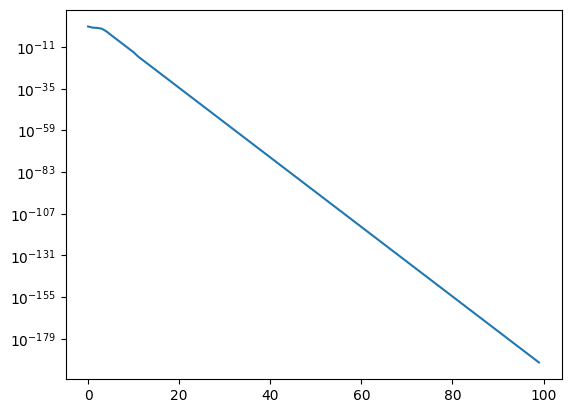

In [11]:
x = np.copy(x_init)
niter = 100
lr = 0.9

loss_hist = []

for i in range(niter):
    loss = f(x)
    grad_x = f_grad(x)
    hess_x = f_hess(x)
    direction = jnp.linalg.solve(hess_x, -grad_x)

    x = x + lr*direction
    loss_hist.append(loss)

plt.plot(loss_hist)
plt.yscale('log')

